In [2]:
import os
from matplotlib import pyplot as plt
from astropy.table import Table
import numpy as np

In [3]:
files = os.listdir('../output/tables/')
catalog = []
for file in files:
    if "table" in file:
        catalog.append(file.split('table_')[1].split('.tbl')[0])
print(catalog)

['glimpse360c', 'glimpse_s07', 'glimpse_s07_ar', 'glimpse3d_v1cat_tbl', 'glimpse2_v2cat']


In [4]:
data = []
for cat in catalog:
    cat_table = Table.read('../output/tables/match_table_'+cat+'.tbl',format='ipac')
    data.append(len(cat_table))

TypeError: 'int' object is not iterable

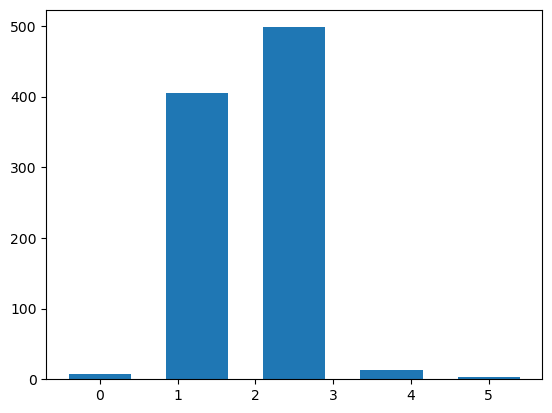

In [ ]:
x = np.linspace(0,len(data),len(data))

_, ax = plt.subplots()

ax.bar(x,data)



ax.set_xticks(x,labels=catalog,rotation=45,ha='center',fontsize='10')
ax.set_title('Catalog match comparison')
ax.set_ylabel('Number of matches')
ax.set_yscale('log')
plt.tight_layout()
plt.savefig('../output/figures/catalog_comparison.pdf',format='pdf')

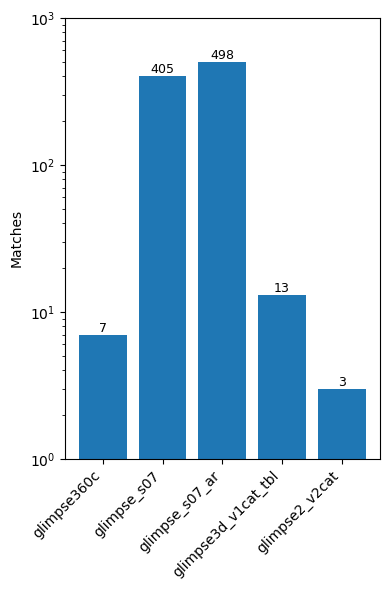

In [8]:
x = np.arange(len(data))

fig, ax = plt.subplots(figsize=(4,6),tight_layout=True)

bars = ax.bar(x, data)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(catalog, rotation=45, ha="right", fontsize=10)
ax.set_ylim(1,1000)
#ax.set_title("Catalog match comparison")
ax.set_ylabel("Matches")
ax.set_yscale("log")

plt.savefig('../output/figures/catalog_comparison.pdf',format='pdf')
plt.show()

    ra    
   deg    
----------
272.718651
272.715814
272.718987
272.720819
272.724464
272.723565
272.721055
272.717133
  272.7272
       ...
259.724628
259.717858
 259.71413
259.720152
259.718368
 259.71743
259.709384
259.715828
259.720295
259.715639
Length = 99116 rows


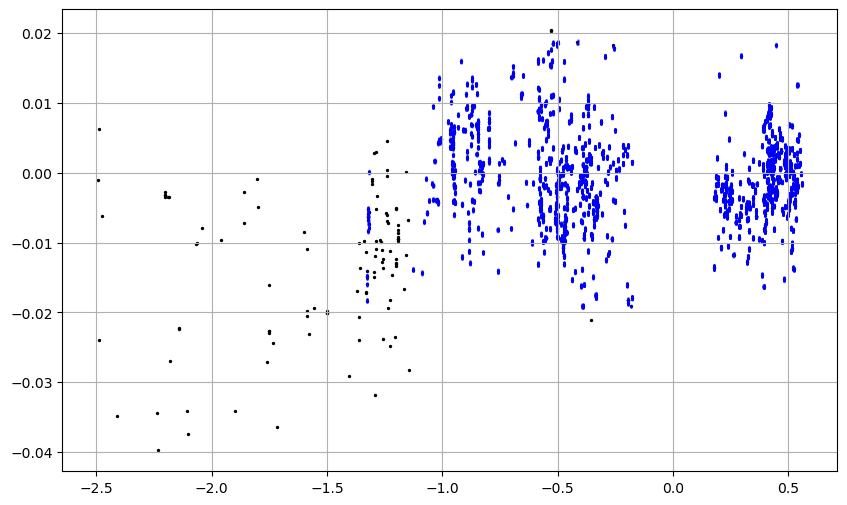

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table, unique
from astropy.coordinates import SkyCoord
import astropy.units as u
import pandas as pd


alma_sources_file = "7MTM2TM1_Core_catalogue_out_official_v3_run6Apr23+16Jan24_sn-5_may24_clump_cat.txt"
alma_sources = Table.from_pandas(
    pd.read_csv(
        "../alma_input/" + alma_sources_file,
        comment="\\",
        skiprows=[2],
        delimiter=r"\s+",
    )
)

alma_file = "almaprops_2024_all_20250219.tab"

alma_regions = Table.read("../alma_input/" + alma_file, format="ascii.ipac")

coords = SkyCoord(alma_regions['GLON'], alma_regions['GLAT'], frame='galactic')

# Convert RA to [-180,180] for Mollweide
ra_rad = coords.galactic.l.wrap_at(180*u.deg).radian
dec_rad = coords.galactic.b.radian

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)

ax.scatter(ra_rad, dec_rad, s=2,color='black')


spitzer_sources = Table.read(
    "../output/tables/spitzer_sources_" + 'glimpse_s07' + ".tbl",
    format="ipac",
)
spitzer_sources = unique(spitzer_sources, keys="designation")

print(spitzer_sources['ra'])

coords = SkyCoord(ra=spitzer_sources['ra'], dec=spitzer_sources['dec'], frame='icrs')

# Convert RA to [-180,180] for Mollweide
ra_rad = coords.galactic.l.wrap_at(180*u.deg).radian
dec_rad = coords.galactic.b.radian

ax.scatter(ra_rad, dec_rad, s=0.5,alpha=0.2,color='blue')

#ax.set_ylim(np.radians(-15), np.radians(15))



ax.grid(True)
